# Apache Airflow: Beginner to Advanced
**Part of: Building Automated Data Pipelines with Spark, dbt and Airflow**

Airflow is the **scheduler and orchestrator**: it decides *when* and *in what order* your Spark jobs, dbt builds and checks run, retries failures and gives you a UI to see everything.

This notebook targets **Airflow 3.x** (`from airflow.sdk import ...`). DAG files are written from the notebook and then executed locally with `airflow dags test`, so you do not need to run a scheduler to learn.

| Level | You will learn |
|---|---|
| 🟢 Beginner | DAGs, tasks, operators, dependencies, running a DAG |
| 🟡 Intermediate | TaskFlow API, XCom, scheduling, retries, templating, trigger rules, Variables |
| 🔴 Advanced | Dynamic task mapping, branching, TaskGroups, sensors, Assets, callbacks, an end-to-end Spark → dbt pipeline, testing, deployment |

> 💡 Airflow runs best on Linux/macOS/WSL2 or Docker. On plain Windows, use WSL2.

In [ ]:
%pip install -q apache-airflow pyspark pandas

## 0. Local setup

In [ ]:
import os, subprocess, textwrap, pathlib

AIRFLOW_HOME = os.path.abspath("airflow_home")
os.environ["AIRFLOW_HOME"] = AIRFLOW_HOME
os.environ["AIRFLOW__CORE__LOAD_EXAMPLES"] = "False"
os.environ["AIRFLOW__CORE__DAGS_FOLDER"] = f"{AIRFLOW_HOME}/dags"
pathlib.Path(f"{AIRFLOW_HOME}/dags").mkdir(parents=True, exist_ok=True)

def sh(cmd, tail=2500):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    print(out[-tail:])
    return r.returncode

def write_dag(name, code):
    p = pathlib.Path(f"{AIRFLOW_HOME}/dags/{name}.py")
    p.write_text(textwrap.dedent(code).lstrip("\n"))
    return p

def list_dags(pattern="."):
    # Airflow 3 lists DAGs from the database; `reserialize` parses the dags/ folder into it
    # (in a real deployment the DAG processor does this continuously).
    sh(f"airflow dags reserialize >/dev/null 2>&1; airflow dags list 2>&1 | grep -E '{pattern}'")

sh("airflow db migrate 2>&1 | tail -3")

---
# 🟢 Level 1 - Beginner

## 1.1 Core concepts
| Term | Meaning |
|---|---|
| **DAG** | *Directed Acyclic Graph*: a workflow = tasks + the order between them (no loops) |
| **Task** | one unit of work |
| **Operator** | a template for a task (`BashOperator`, `PythonOperator`, ...) |
| **DAG run** | one execution of the DAG for a given logical date |
| **Task instance** | one task in one DAG run, with a **state** (queued, running, success, failed, ...) |

## 1.2 The architecture
You write DAG files; the **scheduler** parses them, creates runs and queues tasks; the **executor** sends them to **workers**; everything is recorded in the **metadata DB** and shown in the UI.

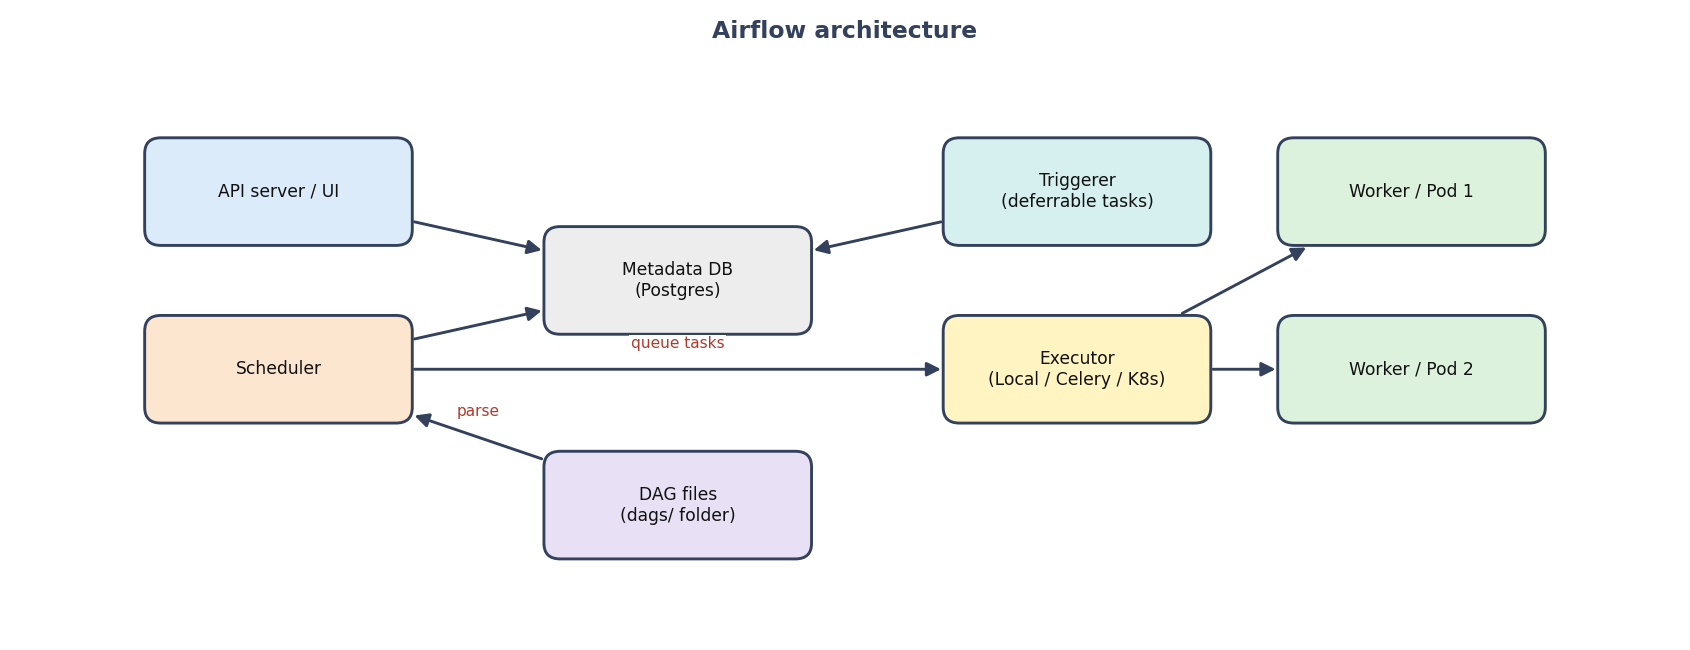

## 1.3 Task states
Every task instance moves through states. Colours in the UI map to these:

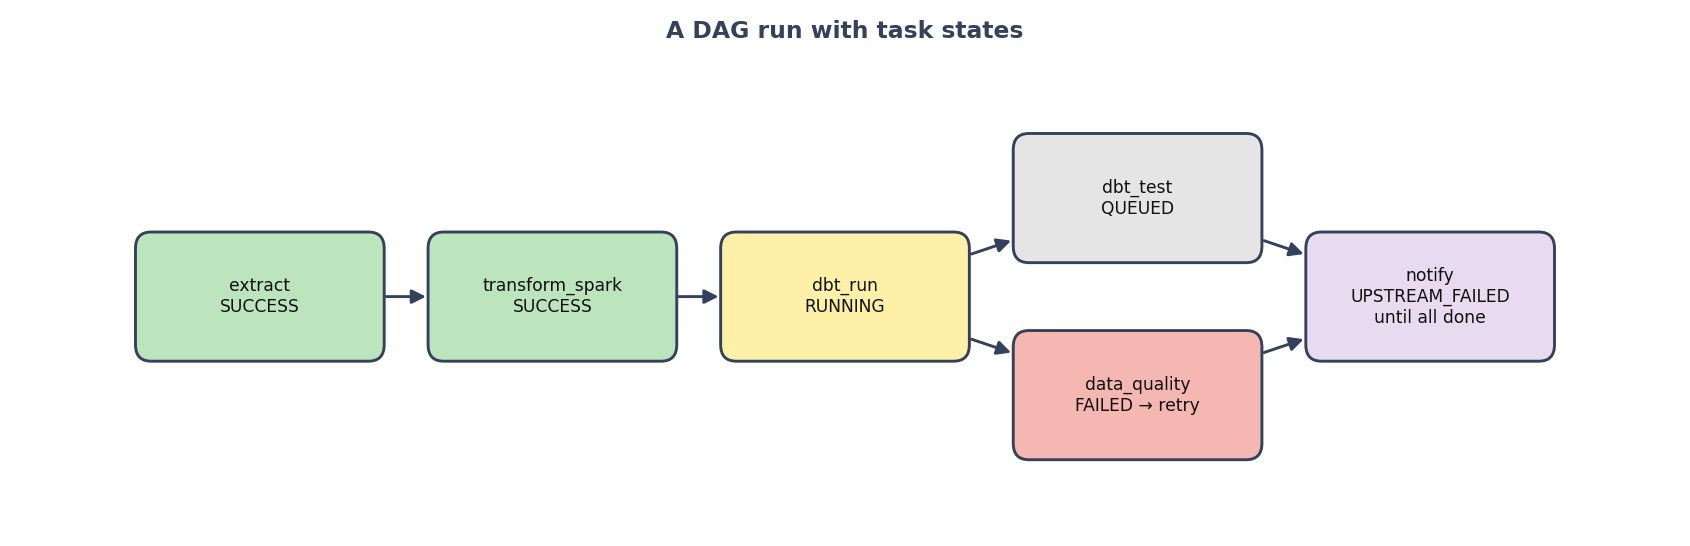

*Downstream tasks wait for upstream success (by default).*

## 1.4 Your first DAG

In [ ]:
write_dag("hello_airflow", '''
    from datetime import datetime
    from airflow.sdk import DAG
    from airflow.providers.standard.operators.bash import BashOperator
    from airflow.providers.standard.operators.python import PythonOperator

    def say_hello():
        print("Hello from a Python task!")

    with DAG(
        dag_id="hello_airflow",
        start_date=datetime(2026, 1, 1),
        schedule=None,          # run only when triggered manually
        catchup=False,
        tags=["beginner"],
    ) as dag:
        print_date = BashOperator(task_id="print_date", bash_command="date")
        hello = PythonOperator(task_id="hello", python_callable=say_hello)
        done = BashOperator(task_id="done", bash_command="echo finished")

        print_date >> hello >> done      # run in this order
''')
list_dags("dag_id|hello_airflow")

## 1.5 Run it
`airflow dags test` runs the whole DAG once in your terminal, which is perfect for development.

In [ ]:
sh("airflow dags test hello_airflow 2>&1 | grep -E 'Hello from|finished|state=|Task|SUCCESS|success' | head -20")

## 1.6 Dependencies
```python
a >> b                  # b after a
a >> [b, c] >> d        # fan-out then fan-in
a.set_downstream(b)     # same as a >> b
```
### ✅ Beginner exercises
1. Add a task that prints your username (`whoami`) between `print_date` and `hello`.
2. Make `done` run after **both** `print_date` and `hello` (`[print_date, hello] >> done`).
3. In the real UI (`airflow standalone`), find the Graph view and the task logs.

---
# 🟡 Level 2 - Intermediate

## 2.1 TaskFlow API (the modern way)
Decorate plain Python functions with `@task`; return values are passed between tasks automatically (via **XCom**), and dependencies are inferred from the function calls.

In [ ]:
write_dag("etl_taskflow", '''
    from datetime import datetime, timedelta
    from airflow.sdk import dag, task

    @dag(
        dag_id="etl_taskflow",
        schedule="@daily",
        start_date=datetime(2026, 1, 1),
        catchup=False,
        default_args={"retries": 2, "retry_delay": timedelta(minutes=1)},
        tags=["intermediate"],
    )
    def etl_taskflow():

        @task
        def extract():
            return [{"order_id": 1, "amount": 120.5}, {"order_id": 2, "amount": 60.0}, {"order_id": 3, "amount": 400.0}]

        @task
        def transform(rows):
            return round(sum(r["amount"] for r in rows), 2)

        @task
        def load(total):
            print(f"Loaded daily revenue = {total}")

        load(transform(extract()))      # extract -> transform -> load

    etl_taskflow()
''')
sh("airflow dags test etl_taskflow 2>&1 | grep -E 'Loaded daily|state=|Marking' | head")

## 2.2 Scheduling
| `schedule=` | Meaning |
|---|---|
| `None` | manual only |
| `"@daily"`, `"@hourly"` | presets |
| `"0 6 * * 1-5"` | cron: 06:00 on weekdays |
| `timedelta(hours=6)` | every 6 hours |
| `[Asset(...)]` | when upstream data is updated (see 3.5) |

* **`start_date`**: first logical date. **`catchup=False`** stops Airflow from back-filling every missed interval.
* The **logical date / `data_interval`** of a run is the period of data it *processes*, and a daily run for Jan 1 starts just after Jan 1 ends.

## 2.3 Retries, timeouts and failure handling
```python
default_args = {
    "retries": 3,
    "retry_delay": timedelta(minutes=5),
    "retry_exponential_backoff": True,
    "execution_timeout": timedelta(hours=1),
}
```
Retries are Airflow's first line of defence for flaky networks and busy clusters.

## 2.4 Templating with Jinja
Airflow renders `{{ ... }}` in many operator fields. Use it so tasks stay **idempotent** (re-running a date gives the same result).

In [ ]:
write_dag("templating_demo", '''
    from datetime import datetime
    from airflow.sdk import DAG
    from airflow.providers.standard.operators.bash import BashOperator

    with DAG("templating_demo", start_date=datetime(2026, 1, 1), schedule="@daily", catchup=False,
             params={"table": "orders"}, tags=["intermediate"]) as dag:
        BashOperator(
            task_id="show_vars",
            bash_command=(
                "echo 'logical date  : {{ ds }}' && "
                "echo 'interval start: {{ data_interval_start }}' && "
                "echo 'param table   : {{ params.table }}' && "
                "echo 'partition path: s3://lake/{{ params.table }}/dt={{ ds }}/'"
            ),
        )
''')
sh("airflow dags test templating_demo 2026-03-15 2>&1 | grep -E 'logical date|interval start|param table|partition path'")

## 2.5 Trigger rules
By default a task runs only if **all** upstream tasks succeeded (`all_success`). Change it for cleanup/notify tasks.

| Rule | Runs when |
|---|---|
| `all_success` (default) | every upstream succeeded |
| `all_done` | every upstream finished, whatever the result (cleanup) |
| `one_failed` | at least one upstream failed (alerting) |
| `none_failed_min_one_success` | nothing failed and something succeeded (after branching) |

In [ ]:
write_dag("trigger_rules_demo", '''
    from datetime import datetime
    from airflow.sdk import DAG, task
    from airflow.providers.standard.operators.bash import BashOperator

    with DAG("trigger_rules_demo", start_date=datetime(2026, 1, 1), schedule=None, catchup=False,
             tags=["intermediate"]) as dag:

        @task
        def flaky():
            raise ValueError("simulated failure")

        notify_failure = BashOperator(task_id="notify_failure", bash_command="echo ALERT: something failed",
                                      trigger_rule="one_failed")
        cleanup = BashOperator(task_id="cleanup", bash_command="echo cleaning temp files",
                               trigger_rule="all_done")

        flaky() >> [notify_failure, cleanup]
''')
sh("airflow dags test trigger_rules_demo 2>&1 | grep -E 'ALERT|cleaning|simulated|Marking' | head")

## 2.6 Variables and Connections
Never hard-code secrets or environment-specific values in DAG files.

* **Variables**: small config values (`airflow variables set data_bucket s3://lake`).
* **Connections**: host, login, password, extras for external systems (databases, S3, Spark, Slack).
* In production, back both with a **secrets backend** (Vault, AWS Secrets Manager, ...).

In [ ]:
sh("airflow variables set data_bucket s3://my-lake && airflow variables get data_bucket")
sh("airflow connections add warehouse_db --conn-type postgres --conn-host localhost --conn-login analytics --conn-password '***' --conn-port 5432 --conn-schema dwh 2>&1 | tail -2")
write_dag("variables_demo", '''
    from datetime import datetime
    from airflow.sdk import dag, task, Variable

    @dag(dag_id="variables_demo", start_date=datetime(2026, 1, 1), schedule=None, catchup=False, tags=["intermediate"])
    def variables_demo():
        @task
        def show():
            # read inside the task (not at module top-level) so parsing stays fast
            print("bucket =", Variable.get("data_bucket"))
        show()
    variables_demo()
''')
sh("airflow dags test variables_demo 2>&1 | grep -E 'bucket =' ")

### ✅ Intermediate exercises
1. Change `etl_taskflow` so `extract` returns rows for `{{ ds }}` (hint: `get_current_context()["ds"]`).
2. Make `flaky()` fail twice then succeed, using `retries=2` and a counter (hint: `context["ti"].try_number`).
3. Create a DAG scheduled `"30 7 * * 1-5"` and check its next runs in the UI.

---
# 🔴 Level 3 - Advanced

## 3.1 Dynamic task mapping
Create a variable number of tasks at **runtime** (one per file, per partition, per customer...). Each mapped task runs in parallel and shows up as `process[0]`, `process[1]`, ...

In [ ]:
write_dag("dynamic_mapping", '''
    from datetime import datetime
    from airflow.sdk import dag, task

    @dag(dag_id="dynamic_mapping", start_date=datetime(2026, 1, 1), schedule=None, catchup=False, tags=["advanced"])
    def dynamic_mapping():

        @task
        def list_files():
            return ["orders_2026_01.csv", "orders_2026_02.csv", "orders_2026_03.csv"]   # could come from S3

        @task
        def process(filename):
            print(f"processing {filename}")
            return len(filename)

        @task
        def summarize(sizes):
            print("files processed:", len(list(sizes)), "| total name length:", sum(sizes))

        summarize(process.expand(filename=list_files()))      # fan-out then fan-in

    dynamic_mapping()
''')
sh("airflow dags test dynamic_mapping 2>&1 | grep -E 'processing|files processed' ")

## 3.2 Branching, TaskGroups and joins
`@task.branch` returns the task id(s) to follow; the others are **skipped**. The task after the branches must use `none_failed_min_one_success`, otherwise it is skipped too.

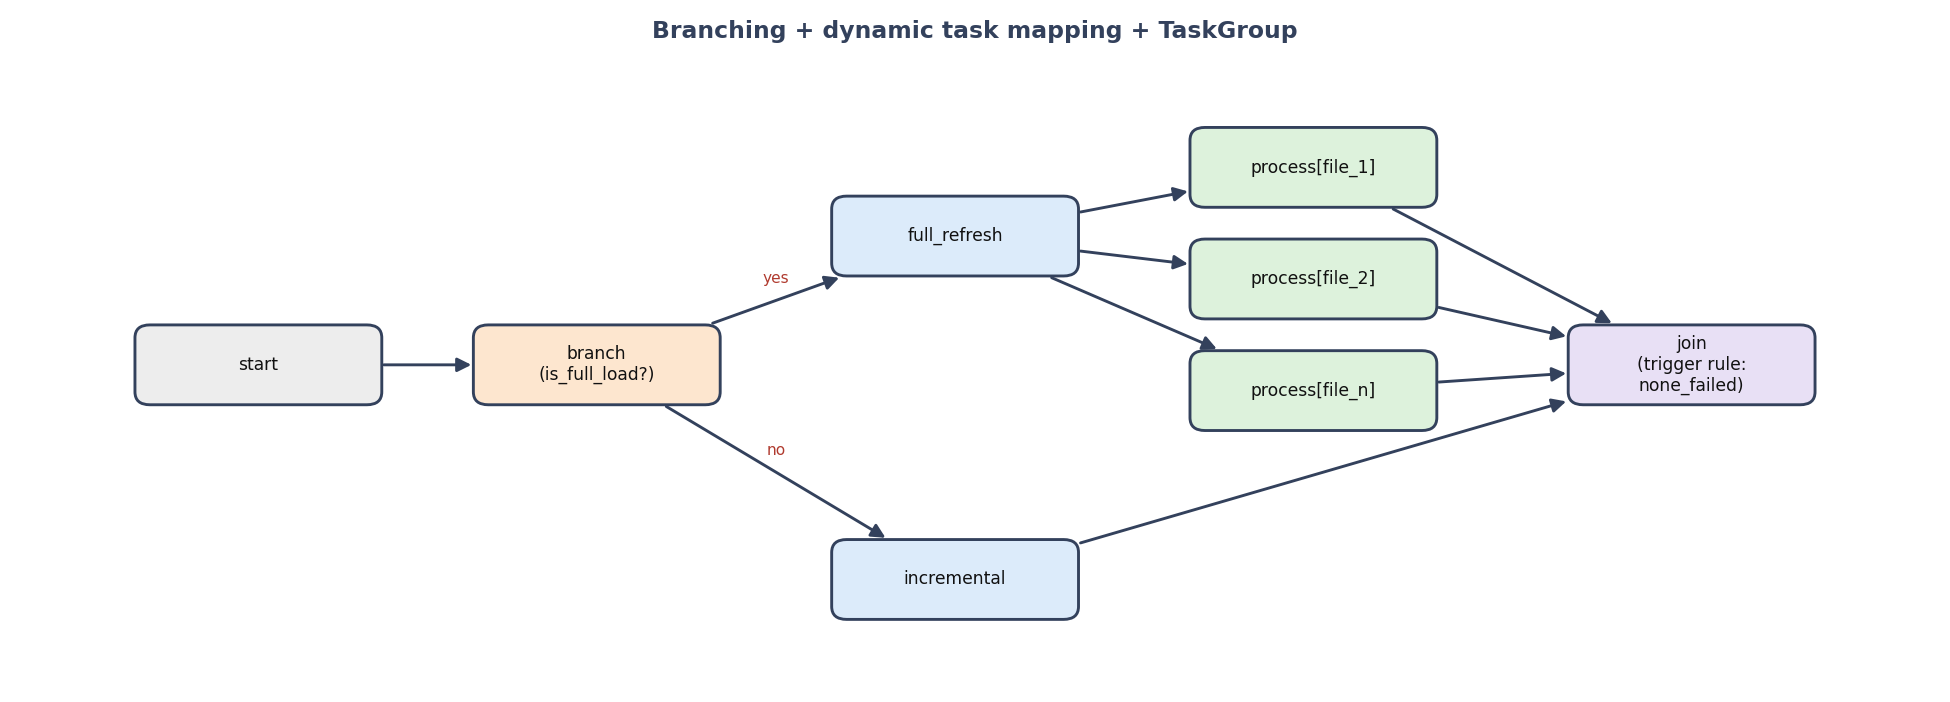

In [ ]:
write_dag("branching_groups", '''
    from datetime import datetime
    from airflow.sdk import dag, task, task_group
    from airflow.providers.standard.operators.empty import EmptyOperator

    @dag(dag_id="branching_groups", start_date=datetime(2026, 1, 1), schedule=None, catchup=False,
         params={"full_load": False}, tags=["advanced"])
    def branching_groups():
        start = EmptyOperator(task_id="start")

        @task.branch
        def choose(params=None):
            return "full_refresh.truncate" if params["full_load"] else "incremental_load"

        @task_group
        def full_refresh():
            @task
            def truncate(): print("truncating target")
            @task
            def reload(): print("reloading everything")
            truncate() >> reload()

        @task
        def incremental_load():
            print("loading only new rows")

        join = EmptyOperator(task_id="join", trigger_rule="none_failed_min_one_success")

        start >> choose() >> [full_refresh(), incremental_load()] >> join

    branching_groups()
''')
sh("airflow dags test branching_groups 2>&1 | grep -E 'loading only|truncating|reloading'")

## 3.3 Sensors: wait for something to happen
Sensors poll until a condition is true (file landed, partition exists, API ready). Use `mode="reschedule"` (or **deferrable** operators) so waiting does not occupy a worker slot.

In [ ]:
write_dag("sensor_demo", '''
    from datetime import datetime, timedelta
    from airflow.sdk import DAG
    from airflow.providers.standard.sensors.filesystem import FileSensor
    from airflow.providers.standard.operators.bash import BashOperator

    with DAG("sensor_demo", start_date=datetime(2026, 1, 1), schedule="@daily", catchup=False, tags=["advanced"]) as dag:
        wait = FileSensor(
            task_id="wait_for_landing_file",
            filepath="/data/landing/orders_{{ ds_nodash }}.csv",
            poke_interval=60,
            timeout=60 * 60 * 3,        # give up after 3 hours
            mode="reschedule",          # free the worker slot between pokes
            soft_fail=False,
        )
        wait >> BashOperator(task_id="ingest", bash_command="echo ingesting")
''')
list_dags("sensor_demo")

## 3.4 Alerts: callbacks
Run a function when a task or DAG fails or succeeds. Plug in Slack, email, PagerDuty here.

In [ ]:
write_dag("callbacks_demo", '''
    from datetime import datetime
    from airflow.sdk import dag, task

    def alert(context):
        ti = context["ti"]
        print(f"ALERT >> task {ti.task_id} failed in dag {ti.dag_id} (try {ti.try_number})")
        # requests.post(SLACK_WEBHOOK, json={...})

    @dag(dag_id="callbacks_demo", start_date=datetime(2026, 1, 1), schedule=None, catchup=False,
         default_args={"on_failure_callback": alert}, tags=["advanced"])
    def callbacks_demo():
        @task
        def boom():
            raise RuntimeError("kaboom")
        boom()
    callbacks_demo()
''')
sh("airflow dags test callbacks_demo 2>&1 | grep -E 'ALERT|kaboom' | head -3")

## 3.5 Assets: data-aware scheduling
Instead of guessing a time, let a DAG run **when upstream data is produced**. A producer task lists an `Asset` in `outlets`; a consumer DAG sets `schedule=[Asset(...)]`.

In [ ]:
write_dag("assets_demo", '''
    from datetime import datetime
    from airflow.sdk import DAG, Asset, task

    silver_orders = Asset("lake://silver/orders")

    with DAG("produce_silver_orders", start_date=datetime(2026, 1, 1), schedule="@daily", catchup=False,
             tags=["advanced"]):
        @task(outlets=[silver_orders])
        def build_silver():
            print("silver orders refreshed")
        build_silver()

    with DAG("consume_silver_orders", start_date=datetime(2026, 1, 1), schedule=[silver_orders], catchup=False,
             tags=["advanced"]):
        @task
        def build_gold():
            print("gold marts rebuilt because silver changed")
        build_gold()
''')
list_dags("silver_orders")

## 3.6 Capstone: orchestrate Spark → dbt → tests
The real goal of this course: a daily DAG that runs your **Spark** job (bronze → silver), then your **dbt** project (marts + tests), and alerts on failure.

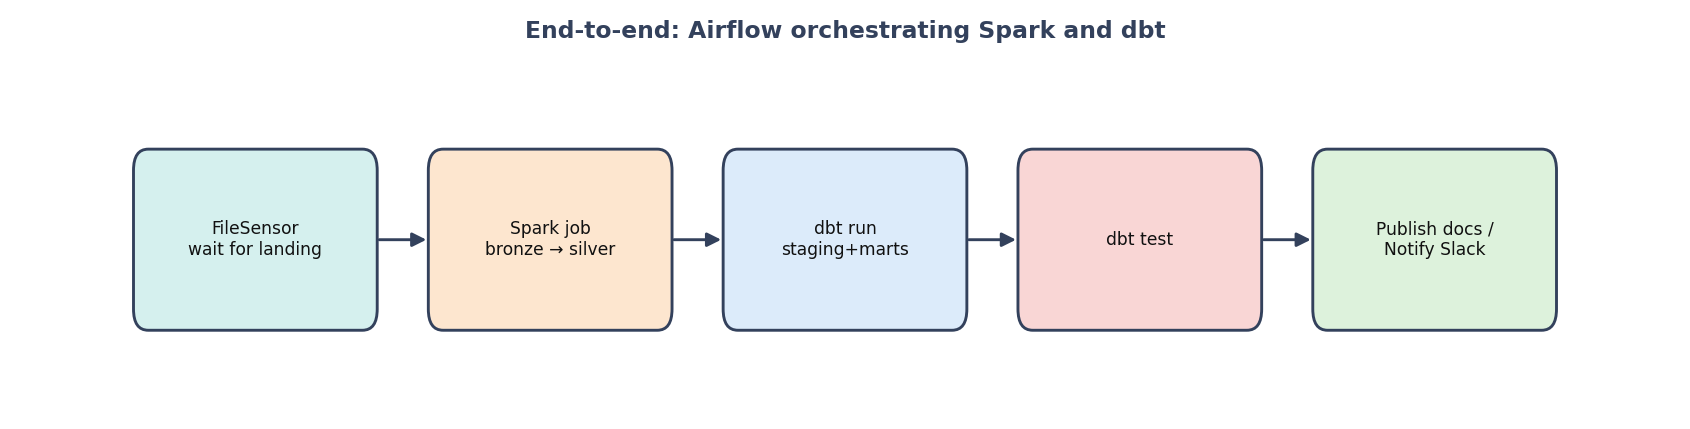

In [ ]:
# 1) the Spark job (a plain PySpark script; in production you'd spark-submit it to a cluster)
JOBS = pathlib.Path("jobs"); JOBS.mkdir(exist_ok=True)
(JOBS / "silver_orders.py").write_text(textwrap.dedent('''
    import sys
    from pyspark.sql import SparkSession, functions as F
    run_date, lake_root = sys.argv[1], sys.argv[2]      # absolute paths: Airflow tasks do NOT run in your notebook folder
    spark = SparkSession.builder.master("local[2]").appName("silver_orders").getOrCreate()
    raw = spark.createDataFrame(
        [(1, "2026-01-05", 2, 95.0), (2, "2026-01-06", 1, 60.0), (2, "2026-01-06", 1, 60.0)],
        ["order_id", "order_date", "qty", "unit_price"])
    silver = (raw.dropDuplicates(["order_id"]).withColumn("revenue", F.col("qty") * F.col("unit_price"))
                 .withColumn("run_date", F.lit(run_date)))
    silver.write.mode("overwrite").parquet(f"{lake_root}/silver/orders/run_date={run_date}")
    print("SILVER ROWS:", silver.count())
    spark.stop()
'''))

# 2) the DAG
DBT_DIR = os.path.abspath("shop_dbt")     # created in notebook 2; change if yours lives elsewhere
LAKE = os.path.abspath("lake")
write_dag("daily_pipeline", f'''
    from datetime import datetime, timedelta
    from airflow.sdk import DAG
    from airflow.providers.standard.operators.bash import BashOperator

    def alert(context):
        print("ALERT >> pipeline task failed:", context["ti"].task_id)

    DBT_DIR = "{DBT_DIR}"
    JOB = "{JOBS.resolve()}/silver_orders.py"
    LAKE = "{LAKE}"

    with DAG(
        dag_id="daily_pipeline",
        start_date=datetime(2026, 1, 1),
        schedule="0 6 * * *",
        catchup=False,
        max_active_runs=1,
        default_args={{"retries": 2, "retry_delay": timedelta(minutes=5), "on_failure_callback": alert}},
        tags=["capstone"],
    ) as dag:

        spark_silver = BashOperator(
            task_id="spark_silver",
            bash_command="python " + JOB + " {{{{ ds }}}} " + LAKE,        # prod: spark-submit --master yarn ...
            execution_timeout=timedelta(hours=1),
        )
        dbt_run = BashOperator(task_id="dbt_run", bash_command=f"cd {{DBT_DIR}} && dbt run --profiles-dir .")
        dbt_test = BashOperator(task_id="dbt_test", bash_command=f"cd {{DBT_DIR}} && dbt test --profiles-dir .")
        publish = BashOperator(task_id="publish_docs", bash_command=f"cd {{DBT_DIR}} && dbt docs generate --profiles-dir .")

        spark_silver >> dbt_run >> dbt_test >> publish
''')
sh("airflow dags list-import-errors 2>&1 | tail -3")
list_dags("daily_pipeline")

In [ ]:
if os.path.exists(DBT_DIR):
    sh("airflow dags test daily_pipeline 2026-03-15 2>&1 | grep -E 'SILVER ROWS|Completed successfully|PASS=|Marking|ALERT' | head -12")
else:
    print("Run notebook 2 first (it creates shop_dbt/), or set DBT_DIR to your dbt project.")

### Where does the time go?
The **Gantt view** in the UI shows task durations, which is the starting point for tuning (e.g. a slow Spark stage dominating the run).

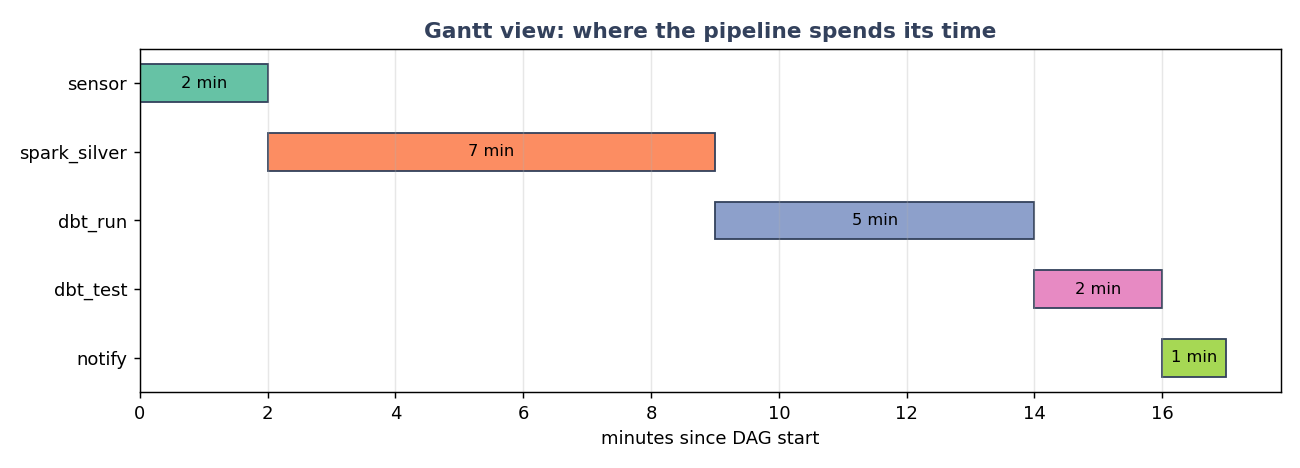

## 3.7 Production patterns
**Design rules**
- **Idempotent tasks**: re-running a date must not duplicate data (overwrite the partition, `MERGE`, or delete+insert).
- **Atomic tasks**: one clear job each, so retries are cheap.
- **No heavy work in the DAG file**: it is parsed constantly. No API calls or DB queries at import time.
- **Do heavy compute elsewhere**: Airflow orchestrates; Spark/dbt/warehouse compute. Don't process big data inside Airflow workers.
- **Use absolute paths / URIs** (`s3://...`): tasks run in their own working directory, not where your DAG file lives.
- **Pass references, not data**: XCom is for small values (paths, counts), not DataFrames.
- Use `pools`, `max_active_tasks` and `max_active_runs` to protect shared systems.

**Running Spark from Airflow**: `SparkSubmitOperator` (provider `apache-airflow-providers-apache-spark`), `DatabricksSubmitRunOperator`, `EmrAddStepsOperator`, `KubernetesPodOperator`, or `BashOperator` + `spark-submit`.

**Running dbt from Airflow**: `BashOperator("dbt build")` is the simplest; **Astronomer Cosmos** renders each dbt model as its own Airflow task.

**Deployment**
| Option | Notes |
|---|---|
| `airflow standalone` | local learning, SQLite |
| Docker Compose | team dev; Postgres + CeleryExecutor |
| Kubernetes + Helm chart | production; KubernetesExecutor (one pod per task) |
| Managed (MWAA, Cloud Composer, Astronomer) | no infrastructure to run |

## 3.8 Testing DAGs
At minimum, test that every DAG **imports without errors** and follows your rules. Put this in CI.

In [ ]:
from airflow.models import DagBag

bag = DagBag(dag_folder=f"{AIRFLOW_HOME}/dags")
assert not bag.import_errors, bag.import_errors

for dag_id, dag in bag.dags.items():
    assert dag.tags, f"{dag_id}: add tags"
    assert dag.catchup is False, f"{dag_id}: catchup should be off unless intended"
print(f"{len(bag.dags)} DAGs loaded, all checks passed ✅")
print(sorted(bag.dags))

### 🏁 Final challenge
Extend `daily_pipeline` so that: (1) a `FileSensor` waits for the landing file, (2) the Spark step is mapped over three regions with `.expand()`, (3) a Slack/email callback fires on failure, and (4) `dbt_test` failing prevents `publish_docs` from running.

### 📚 You now have the full stack
**Spark** (notebook 1) transforms big data → **dbt** (notebook 2) models and tests it in SQL → **Airflow** (this notebook) schedules and monitors both.